# Terrain de jeu : consommation énergétique de 7 sites (2023-2024)

Ce notebook explore le dataset horaire `all_sites_combined.csv` (7 sites, 17 521 heures chacun).

**Comment l'utiliser**
- Exécutez les cellules de haut en bas (*Run All*), puis modifiez les **réglages** de la section 3 (site, dates, seuil) et relancez les cellules suivantes.
- Prérequis : `pip install pandas matplotlib ipykernel` dans le venv, et ce venv sélectionné comme *kernel*.
- Aucun fichier n'est écrit : tout reste dans le notebook.

## 1. Chargement

Les fichiers csv doivent se trouver dans le dossier /data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# --- Affichage -------------------------------------------------------------
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# --- Si le CSV n'est pas trouvé automatiquement, mettez son chemin ici -------
CSV_PATH = None  # exemple : r"C:\Users\...\ml\data\all_sites_combined.csv"


def trouver_fichier(nom):
    """Cherche un fichier par son nom dans le dossier courant, ses parents et leurs dossiers data/."""
    bases = [Path.cwd(), *list(Path.cwd().parents)[:3]]
    for base in bases:
        for sous in ("", "data", "ml/data"):
            dossier = base / sous
            if not dossier.is_dir():
                continue
            # recherche récursive uniquement dans les dossiers data/ (pas dans .venv)
            trouve = next(dossier.rglob(nom) if sous else dossier.glob(nom), None)
            if trouve:
                return trouve
    return None


chemin = Path(CSV_PATH) if CSV_PATH else trouver_fichier("all_sites_combined.csv")
if chemin is None or not chemin.exists():
    raise FileNotFoundError("all_sites_combined.csv introuvable : renseignez CSV_PATH ci-dessus.")

df = pd.read_csv(chemin, parse_dates=["timestamp"])
df = df.sort_values(["site_id", "timestamp"]).reset_index(drop=True)

print(f"Fichier : {chemin}")
print(
    f"{len(df):,} lignes, {df['site_id'].nunique()} sites, du {df['timestamp'].min()} au {df['timestamp'].max()}"
)
display(df.head())

Fichier : c:\Users\mboyadjian2024\Documents\GitHub\smart_energy_optimizer\ml\data\all_sites_combined.csv
122,647 lignes, 7 sites, du 2023-01-01 00:00:00 au 2024-12-31 00:00:00


,timestamp,site_id,site_type,site_name,consumption_kwh,consumption_euros,temperature_celsius,humidity_percent,solar_irradiance_wm2,hour,day_of_week,day_name,month,is_weekend,is_working_hours
0,2023-01-01 00:00:00,SITE001,office,Bureau Tertiaire,85.82,12.87,10.6,76.7,0.0,0,6,Sunday,1,1,0
1,2023-01-01 01:00:00,SITE001,office,Bureau Tertiaire,89.84,13.48,12.0,70.6,0.0,1,6,Sunday,1,1,0
2,2023-01-01 02:00:00,SITE001,office,Bureau Tertiaire,80.62,12.09,13.8,62.2,0.0,2,6,Sunday,1,1,0
3,2023-01-01 03:00:00,SITE001,office,Bureau Tertiaire,92.67,13.90,9.4,66.0,0.0,3,6,Sunday,1,1,0
4,2023-01-01 04:00:00,SITE001,office,Bureau Tertiaire,72.50,10.88,14.8,67.2,41.5,4,6,Sunday,1,1,0


Colonnes : `consumption_kwh` (consommation de l'heure), `consumption_euros` (coût), `temperature_celsius`, `humidity_percent`, `solar_irradiance_wm2` (ensoleillement), puis des colonnes calendaires (`hour`, `day_of_week`, `day_name`, `month`, `is_weekend`, `is_working_hours`).

## 2. Qualité des données

In [2]:
# --- Valeurs manquantes -------------------------------------------------------
colonnes_mesure = [
    "consumption_kwh",
    "consumption_euros",
    "temperature_celsius",
    "humidity_percent",
    "solar_irradiance_wm2",
]

print("% de valeurs manquantes par colonne :")
display(df[colonnes_mesure].isna().mean().mul(100).round(2).rename("% nuls").to_frame())

print("% de valeurs manquantes par site :")
display(df.groupby("site_id")[colonnes_mesure].apply(lambda g: g.isna().mean() * 100).round(1))

% de valeurs manquantes par colonne :


,% nuls
consumption_kwh,2.32
consumption_euros,2.03
temperature_celsius,2.79
humidity_percent,2.79
solar_irradiance_wm2,3.23


% de valeurs manquantes par site :


,consumption_kwh,consumption_euros,temperature_celsius,humidity_percent,solar_irradiance_wm2
site_id,,,,,
SITE001,2.3,2.1,2.8,2.8,3.2
SITE002,2.3,2.0,2.8,2.8,3.2
SITE003,2.3,2.0,2.8,2.8,3.3
SITE004,2.3,2.0,2.8,2.8,3.3
SITE005,2.3,2.0,2.8,2.8,3.2
SITE006,2.3,2.0,2.8,2.8,3.2
SITE007,2.3,2.0,2.7,2.7,3.2


In [3]:
# --- Les valeurs manquantes sont-elles isolées ou en blocs (pannes) ? ----------
def blocs_nuls(serie):
    """Longueur (en heures) de chaque série consécutive de valeurs manquantes."""
    est_nul = serie.isna()
    num_bloc = (est_nul != est_nul.shift()).cumsum()
    longueurs = est_nul.groupby(num_bloc).sum()
    return longueurs[longueurs > 0]


stats = {}
for site, g in df.groupby("site_id"):
    b = blocs_nuls(g["consumption_kwh"])
    stats[site] = {"nb de blocs": len(b), "durée médiane (h)": b.median(), "durée max (h)": b.max()}
display(pd.DataFrame(stats).T)

,nb de blocs,durée médiane (h),durée max (h)
SITE001,148.0,2.0,12.0
SITE002,156.0,1.0,11.0
SITE003,147.0,2.0,11.0
SITE004,143.0,2.0,8.0
SITE005,157.0,2.0,10.0
SITE006,147.0,2.0,8.0
SITE007,151.0,2.0,8.0


In [4]:
# --- Contrôles de cohérence ---------------------------------------------------
# 1) Trous ou doublons dans le calendrier horaire
ctrl = {}
for site, g in df.groupby("site_id"):
    attendu = pd.date_range(g["timestamp"].min(), g["timestamp"].max(), freq="h")
    ctrl[site] = {
        "heures manquantes": len(attendu.difference(g["timestamp"])),
        "doublons": int(g["timestamp"].duplicated().sum()),
    }
print("Calendrier horaire :")
display(pd.DataFrame(ctrl).T)

# 2) Prix du kWh : constant ?
prix = (df["consumption_euros"] / df["consumption_kwh"]).replace([np.inf, -np.inf], np.nan)
print("Prix implicite (euros / kWh) :")
display(prix.describe().round(3).to_frame("prix"))

# 3) Ensoleillement la nuit (devrait être nul)
nuit = df[df["hour"].isin([0, 1, 2, 3, 22, 23])]
print(
    f"Heures de nuit avec ensoleillement > 0 : {(nuit['solar_irradiance_wm2'] > 0).mean():.2%}  "
    f"(max = {nuit['solar_irradiance_wm2'].max():.0f} W/m2)"
)

# 4) Consommations nulles ou négatives
print(
    f"Consommation = 0 : {(df['consumption_kwh'] == 0).sum()} heures | < 0 : {(df['consumption_kwh'] < 0).sum()} heures"
)

Calendrier horaire :


,heures manquantes,doublons
SITE001,0,0
SITE002,0,0
SITE003,0,0
SITE004,0,0
SITE005,0,0
SITE006,0,0
SITE007,0,0


Prix implicite (euros / kWh) :


,prix
count,118015.00
mean,0.15
std,0.00
min,0.15
25%,0.15
50%,0.15
75%,0.15
max,0.15


Heures de nuit avec ensoleillement > 0 : 48.39%  (max = 208 W/m2)
Consommation = 0 : 1792 heures | < 0 : 0 heures


## 3. Réglages (à modifier puis relancer les cellules suivantes)

In [5]:
DEBUT = "2023-01-01"  # période étudiée
FIN = "2024-12-31"
SEUIL_Z = 4.0  # sensibilité de la détection d'anomalies (section 7) : plus grand = moins d'alertes

## 4. Consommation dans le temps

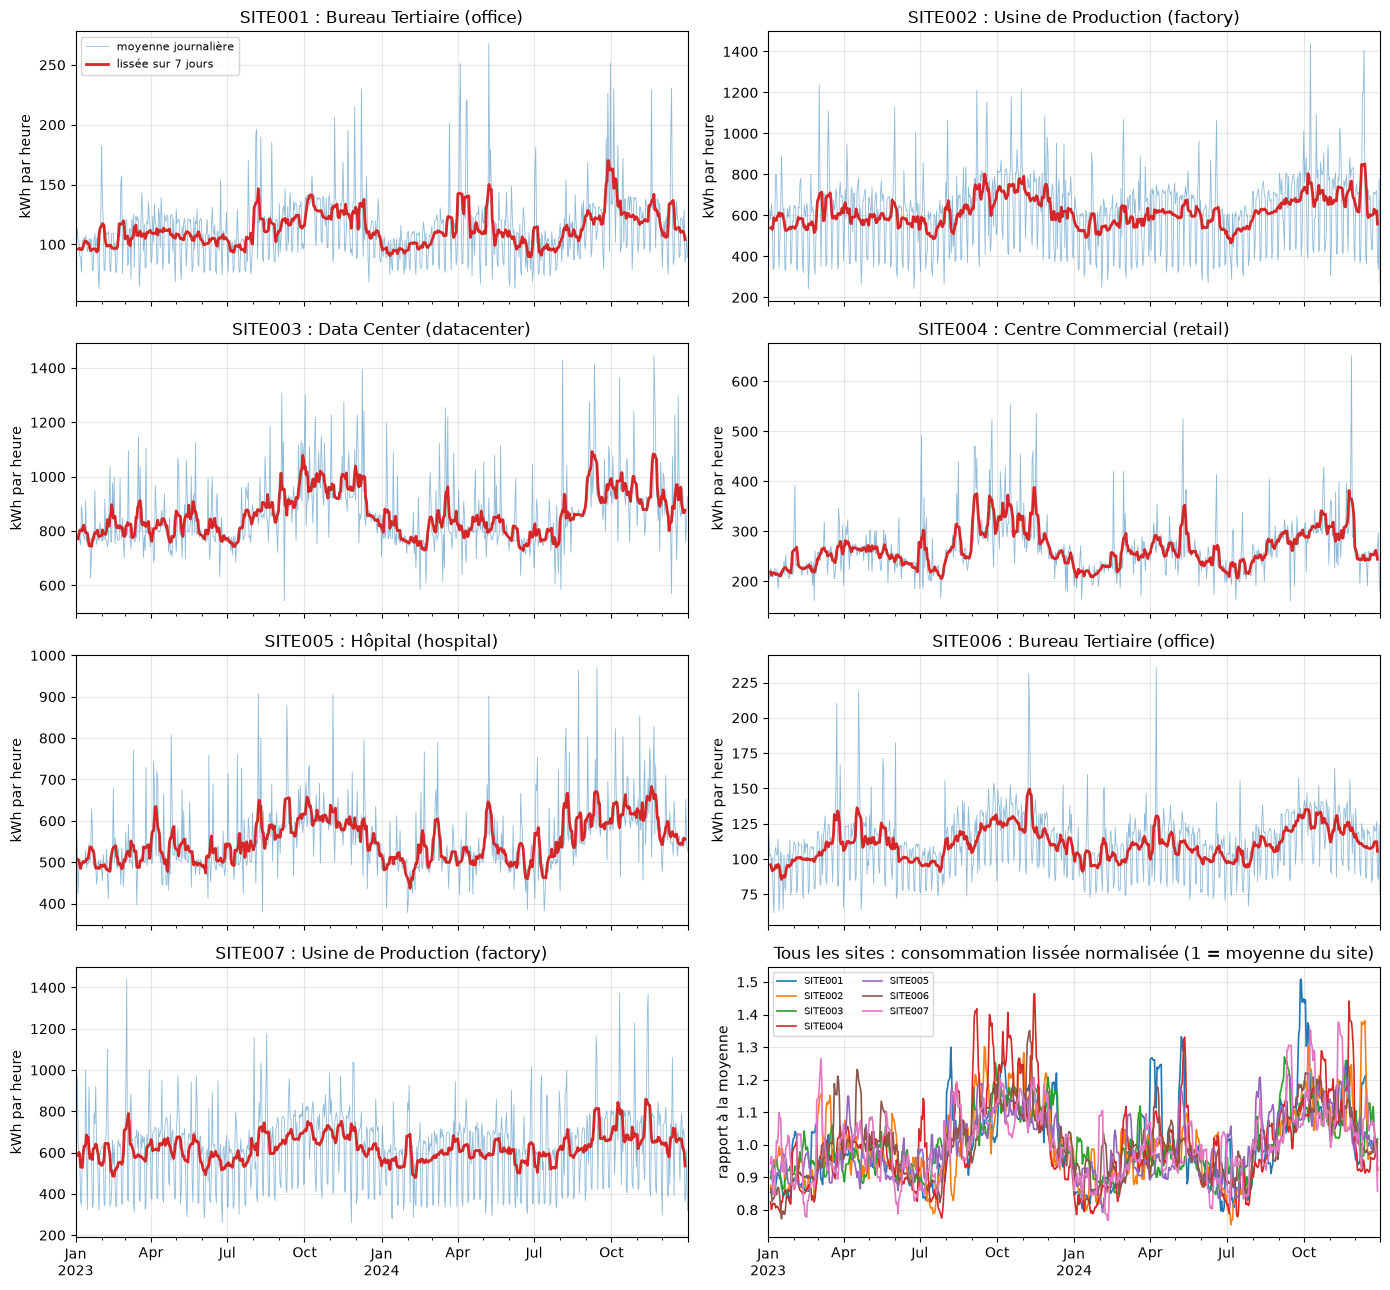

In [7]:
# Consommation moyenne par jour pour chaque site, sur la période DEBUT -> FIN
periode = df[(df["timestamp"] >= DEBUT) & (df["timestamp"] <= FIN)]
jour = (
    periode.pivot_table(index="timestamp", columns="site_id", values="consumption_kwh")
    .resample("D")
    .mean()
)
lisse = jour.rolling(7, center=True).mean()  # moyenne glissante sur 7 jours

fiche = df.groupby("site_id")[["site_name", "site_type"]].first()  # pour les titres

# a) un graphique par site (bleu : moyenne journalière, rouge : lissée sur 7 jours)
fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharex=True)
for ax, site in zip(axes.flat, jour.columns):
    ax.plot(
        jour.index, jour[site], lw=0.6, alpha=0.5, color="tab:blue", label="moyenne journalière"
    )
    ax.plot(lisse.index, lisse[site], lw=2, color="tab:red", label="lissée sur 7 jours")
    ax.set(
        title=f"{site} : {fiche.loc[site, 'site_name']} ({fiche.loc[site, 'site_type']})",
        ylabel="kWh par heure",
    )
axes.flat[0].legend(fontsize=8)

# b) dernier emplacement : tous les sites ensemble, normalisés (1 = moyenne du site) pour comparer les formes
ax = axes.flat[len(jour.columns)]
(lisse / lisse.mean()).plot(ax=ax, lw=1.2)
ax.set(
    title="Tous les sites : consommation lissée normalisée (1 = moyenne du site)",
    xlabel="",
    ylabel="rapport à la moyenne",
)
ax.legend(ncol=2, fontsize=7)

for ax in axes.flat[len(jour.columns) + 1 :]:  # cases inutilisées
    ax.axis("off")

plt.tight_layout()
plt.show()

Ce que ça montre :
- Une saisonnalité commune sur l'ensemble des sites, la consommation est plus haute de septembre à novembre. La case en bas à droite confirme que les sites suivent la même forme
- Les sites sont de tailles différentes
- Les sites ne sont pas tous aussi réguliers, les data center et hôpital sont moins marqué, leur consommation dépend peu du jour de la semaines --> hypothèse : contrairement aux usines et bureaux, les hopitaux et data centers ne sont jamais fermés